# Gene Ranking
When trying to understand the velocities produced by methods such as `MultiVelo` or `scVelo`, it is interesting to test when the velocities degrade and by what metrics genes can be ranked and subsetted. This script tests a few of these ideas and builds subsets of genes based on aggregating several output metrics. 

In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import anndata
import os
import pickle
import warnings
import itertools

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import cut_tree, linkage
from scipy.stats import wilcoxon
from scipy.stats import rankdata
from scipy.stats import rankdata, mannwhitneyu, spearmanr

from sklearn.metrics import silhouette_score as ss
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import cosine_similarity

import scvelo as scv
import multivelo as mv

warnings.filterwarnings("ignore")

In [2]:
python_data_dir = r"C:\Users\Nikla\Documents\MoBi_Master_FS.3\Internship AG Höfer\DynaVelo_testing\data"

scv.settings.verbosity = 3
scv.settings.presenter_view = True
scv.set_figure_params('scvelo')
scv.settings.figdir = rf"{python_data_dir}\multivelo_comparison"
scv.settings.plot_prefix = ""
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 200)
np.set_printoptions(suppress=True)

## Load all MultiVelo data

computing velocity graph (using 8/8 cores)


  0%|          | 0/5241 [00:00<?, ?cells/s]

    finished (0:00:40) --> added 
    'velo_s_norm_graph', sparse matrix with cosine correlations (adata.uns)
computing latent time using root_cells_manual, end_cells_manual as prior
    finished (0:00:03) --> added 
    'latent_time', shared time (adata.obs)
computing velocity embedding
    finished (0:00:04) --> added
    'velo_s_norm_umap', embedded velocity vectors (adata.obsm)


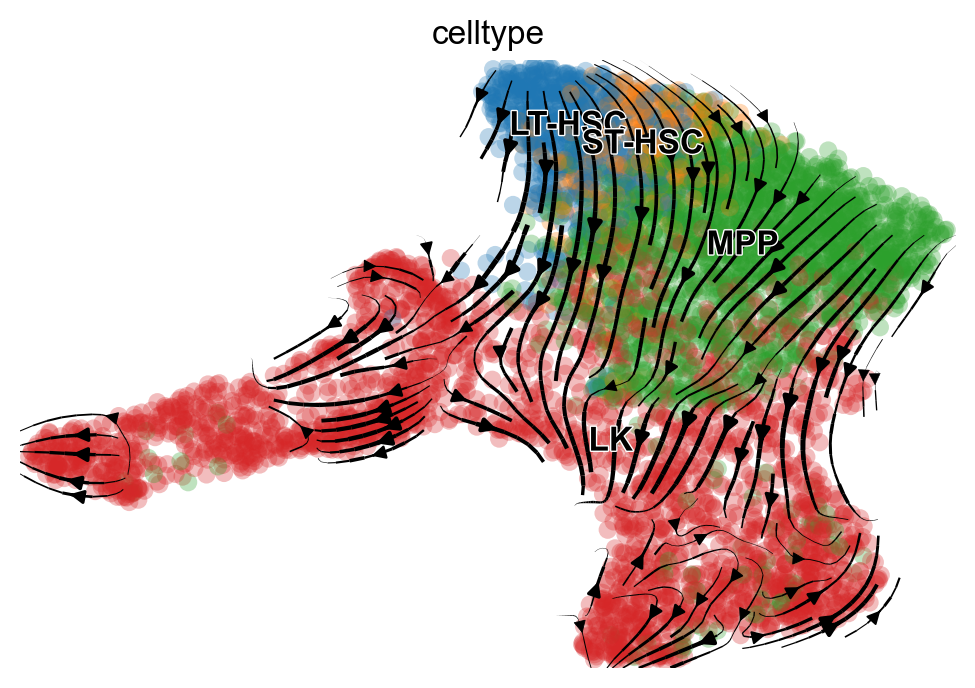

In [3]:
mv_data = sc.read_h5ad(rf"{python_data_dir}\multivelo_results_v3.h5ad")
mv_data.obs["root_cells_manual"] = mv_data.obs["celltype"] == "LT-HSC"
mv_data.obs["end_cells_manual"] = mv_data.obs["celltype"] == "LK"

# prep MultiVelo data some more
mv.velocity_graph(mv_data, n_jobs=8)
mv.latent_time(mv_data, root_key="root_cells_manual", end_key="end_cells_manual")
mv.velocity_embedding_stream(mv_data, basis='umap', color='celltype')

## Load all scVelo Data
This is only necessary when running the code at the end of the script that uses the top ranked genes determined from the `MultiVelo` output to subset the input of `scVelo`, in the hopes of improving this result

In [4]:
total_counts_path = rf"{python_data_dir}\all_rna_counts.h5ad"
adata_rna = sc.read_h5ad(total_counts_path)

adata_rna.obs["root_cells_manual"] = adata_rna.obs["cell_type"] == "LT-HSC"
adata_rna.obs["end_cells_manual"] = adata_rna.obs["cell_type"] == "LK"

computing moments based on connectivities
    finished (0:00:02) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
recovering dynamics (using 8/8 cores)
The correlation threshold has been reduced to -0.0282.
Please be cautious when interpreting results.


  0%|          | 0/1423 [00:00<?, ?gene/s]

    finished (0:05:19) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
computing velocities
The correlation threshold has been reduced to -0.143.
Please be cautious when interpreting results.
    finished (0:00:07) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/8 cores)


  0%|          | 0/5380 [00:00<?, ?cells/s]

    finished (0:00:05) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
computing latent time using root_cells_manual, end_cells_manual as prior
    finished (0:00:05) --> added 
    'latent_time', shared time (adata.obs)
computing velocities
    finished (0:00:12) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/8 cores)


  0%|          | 0/5380 [00:00<?, ?cells/s]

    finished (0:00:08) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:02) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


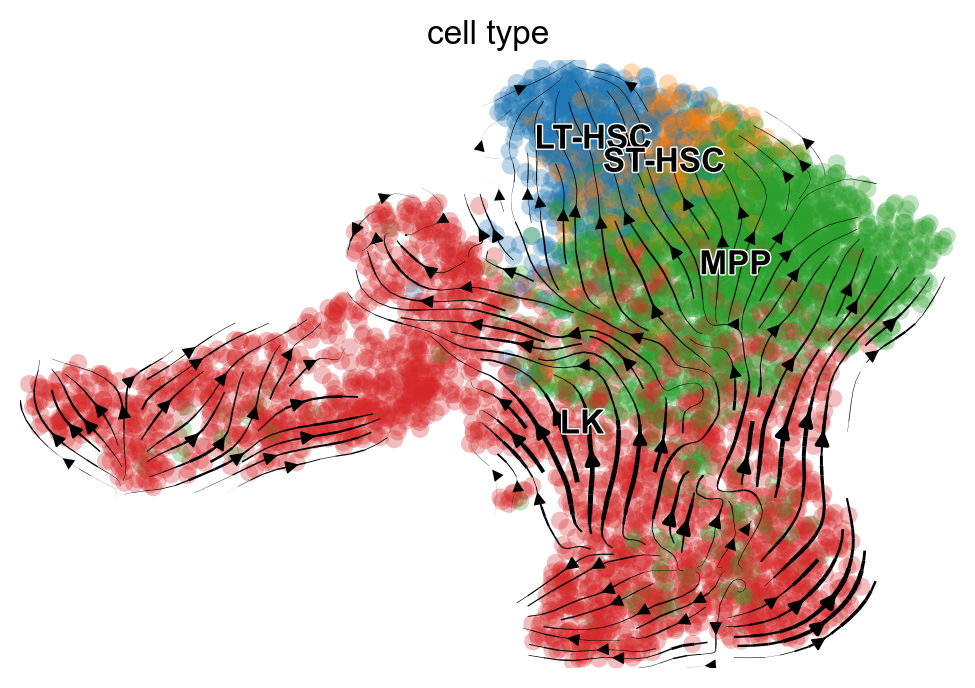

In [5]:
embedding_genes = pd.read_csv(rf"{python_data_dir}\peak_on_peaks_10_comps.csv", header=[0]).T.values.tolist()[0]

adata_rna.var['highly_variable'] = adata_rna.var_names.isin(embedding_genes)
scv.pp.moments(adata_rna, n_neighbors=10)

scv.tl.recover_dynamics(adata_rna, n_jobs=8)
scv.tl.latent_time(adata_rna, root_key="root_cells_manual", end_key="end_cells_manual")

scv.tl.velocity(adata_rna, mode='dynamical')
scv.tl.velocity_graph(adata_rna)

scv.pl.velocity_embedding_stream(adata_rna, basis='umap', color='cell_type')

## Test different options for gene ranking/subsetting

In [6]:
v = mv_data.var
gate = v['velo_s_genes'].astype(bool)

V = np.asarray(mv_data.layers['velo_s'])  # expression change
S = np.asarray(mv_data.layers['Ms'])  # smooth expression values

fit_t = mv_data.layers["fit_t"]
rms = np.sqrt(np.nanmean(V**2, axis=0))
rng = np.nanpercentile(S, 95, axis=0) - np.nanpercentile(S, 5, axis=0)  # This is a robust estimate of the range of expression
rel_mag = rms / (rng + 1e-8)  # This puts velocity on a relative scale to the overall expression

df = pd.DataFrame({
    'lik': v['fit_likelihood'],
    'lik_c': v['fit_likelihood_c'],
    'rel_mag': rel_mag,
    'coverage': (np.nanpercentile(fit_t, 95, axis=0) - np.nanpercentile(fit_t, 5, axis=0)),
}, index=mv_data.var_names)[gate]

ranks = df[['lik', 'rel_mag', 'coverage']].apply(lambda c: rankdata(-c) / len(c))
df['score'] = np.exp(np.log(ranks).mean(axis=1))   # geometric mean of ranks; lower = better

In [7]:
T  = np.asarray(mv_data.layers['fit_t'])           # cells x genes fit of gene times
lt = mv_data.obs['latent_time'].values
plt_ = rankdata(lt) / len(lt)                      # global latent-time percentile

end  = lt >= np.nanquantile(lt, 0.95)
root = lt >= np.nanquantile(lt, 0.05)

def gene_metrics(t):
    ok = np.isfinite(t)

    if ok.sum() < 50 or np.ptp(t[ok]) == 0:  # Failsafe, to make sure there are at least 50 valid cells
        return dict(auroc=np.nan, dev_root=np.nan, dev_end=np.nan, rho=np.nan)
    
    p = np.full_like(t, np.nan, dtype=float)
    p[ok] = rankdata(t[ok], method='average') / ok.sum()
    r, e = root & ok, end & ok  # select cells of the root and end celltypes that pass the filters

    if r.sum() < 5 or e.sum() < 5:  # Another failsafe
        return dict(auroc=np.nan, dev_root=np.nan, dev_end=np.nan, rho=np.nan)
    
    u = mannwhitneyu(t[e], t[r]).statistic

    return dict(
        auroc=u / (e.sum() * r.sum()),
        dev_root=np.mean(np.abs(p[r] - plt_[r])),
        dev_end=np.mean(np.abs(p[e] - plt_[e])),
        rho=spearmanr(t[ok], lt[ok])[0],
    )

gate = mv_data.var['velo_s_genes'].astype(bool).values
res = pd.DataFrame([gene_metrics(T[:, j]) for j in range(T.shape[1])],
                   index=mv_data.var_names)[gate].dropna()

res['dev'] = (res['dev_root'] + res['dev_end']) / 2
res['score'] = (rankdata(-res['auroc']) + rankdata(res['dev']) + rankdata(-res['rho'])) / (3 * len(res))

## Building different subsets
We test two options:
- Using the aggregated (average) value between the liklihood, magnitude and coverage scores
- Using the per gene fit t compared against the overall latent time to check matching
Because these velocity methods fit each gene separately to the mathematical model and solve the ODE per gene, this allows for a simple subsetting before running the velocity calculation, making it unnecessary to rerun the entire `MultiVelo` code.

In [8]:
lik_mag_cov = df.sort_values("score", ascending=False)

In [9]:
lik_mag_cov["top25"] = 25*[True] + (len(lik_mag_cov)-25)*[False]
lik_mag_cov["top50"] = 50*[True] + (len(lik_mag_cov)-50)*[False]
lik_mag_cov["top100"] = 100*[True] + (len(lik_mag_cov)-100)*[False]

metrics = ["lik", "lik_c", "rel_mag", "coverage"]
lik_mag_cov[metrics] = lik_mag_cov[metrics] / lik_mag_cov[metrics].max()

In [10]:
lt_t = res.sort_values("score", ascending=False)

computing velocity graph (using 8/8 cores)


  0%|          | 0/5241 [00:00<?, ?cells/s]

    finished (0:00:13) --> added 
    'velo_s_norm_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:02) --> added
    'velo_s_norm_umap', embedded velocity vectors (adata.obsm)


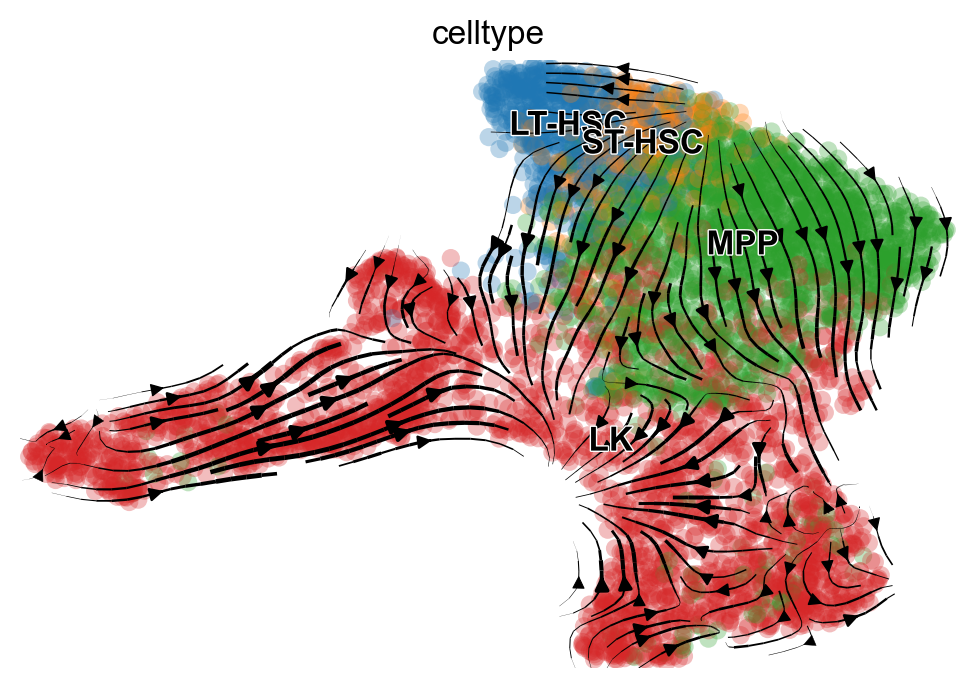

computing velocity graph (using 8/8 cores)


  0%|          | 0/5241 [00:00<?, ?cells/s]

    finished (0:00:18) --> added 
    'velo_s_norm_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:03) --> added
    'velo_s_norm_umap', embedded velocity vectors (adata.obsm)


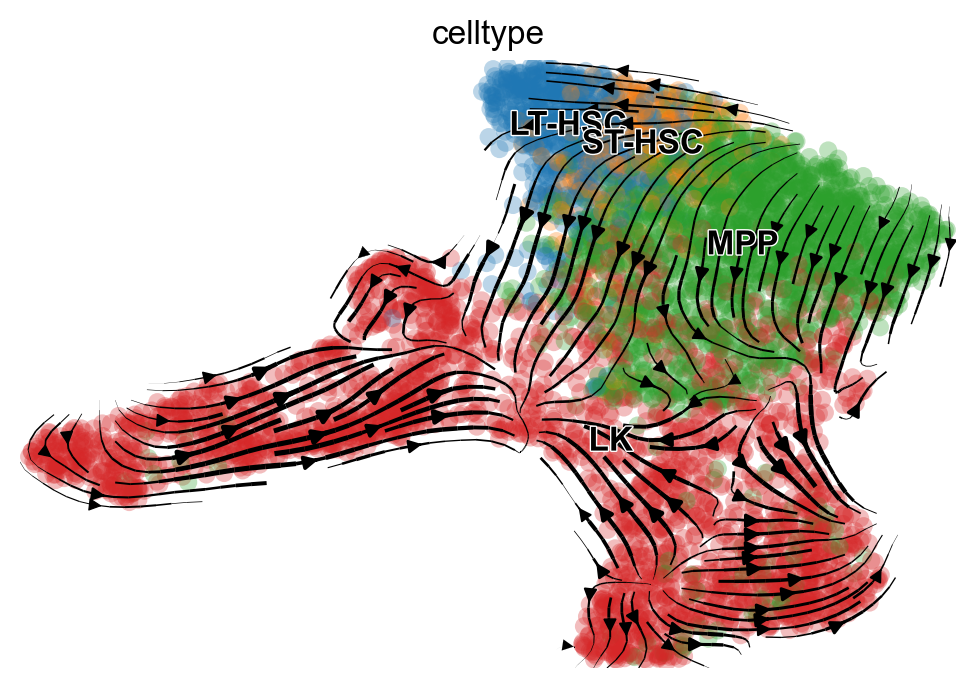

computing velocity graph (using 8/8 cores)


  0%|          | 0/5241 [00:00<?, ?cells/s]

    finished (0:00:21) --> added 
    'velo_s_norm_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:03) --> added
    'velo_s_norm_umap', embedded velocity vectors (adata.obsm)


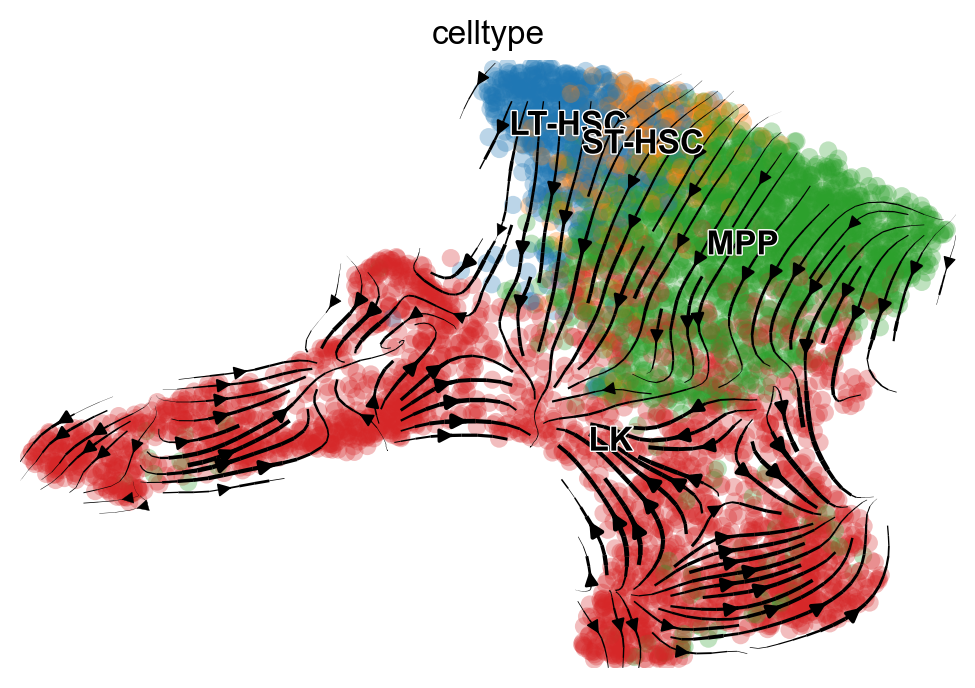

computing velocity graph (using 8/8 cores)


  0%|          | 0/5241 [00:00<?, ?cells/s]

    finished (0:00:17) --> added 
    'velo_s_norm_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:03) --> added
    'velo_s_norm_umap', embedded velocity vectors (adata.obsm)


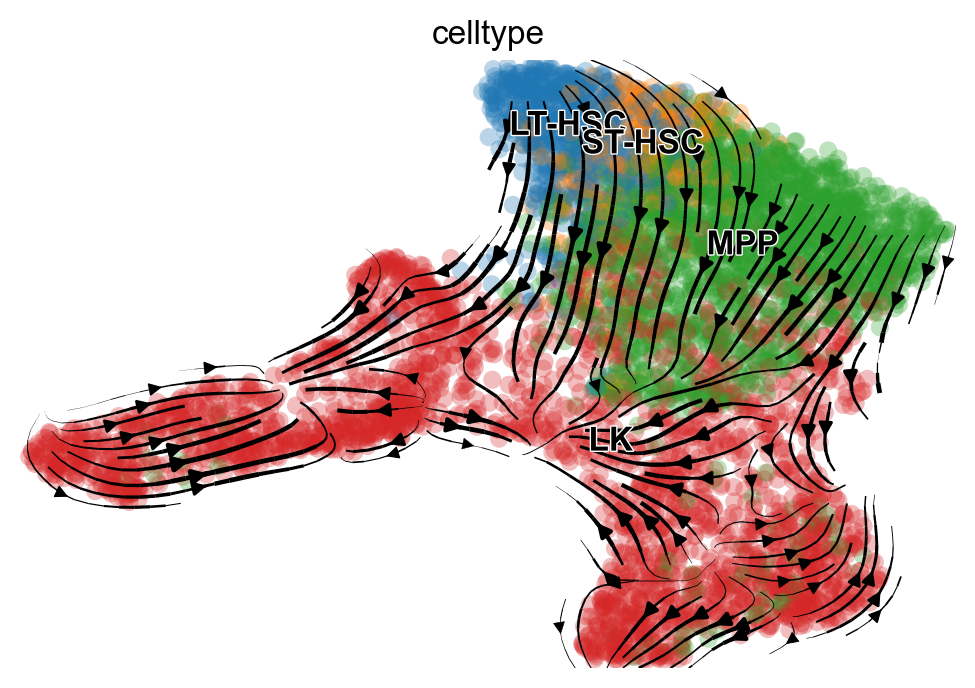

In [11]:
for s in [25, 50, 100, 200]:
    gene_subset = lik_mag_cov[:s].index.to_list()    
    sub = mv_data[:, gene_subset].copy()
    mv.velocity_graph(sub, n_jobs=8)
    mv.velocity_embedding_stream(sub, basis='umap', color='celltype')

computing velocity graph (using 8/8 cores)


  0%|          | 0/5241 [00:00<?, ?cells/s]

    finished (0:00:14) --> added 
    'velo_s_norm_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:02) --> added
    'velo_s_norm_umap', embedded velocity vectors (adata.obsm)


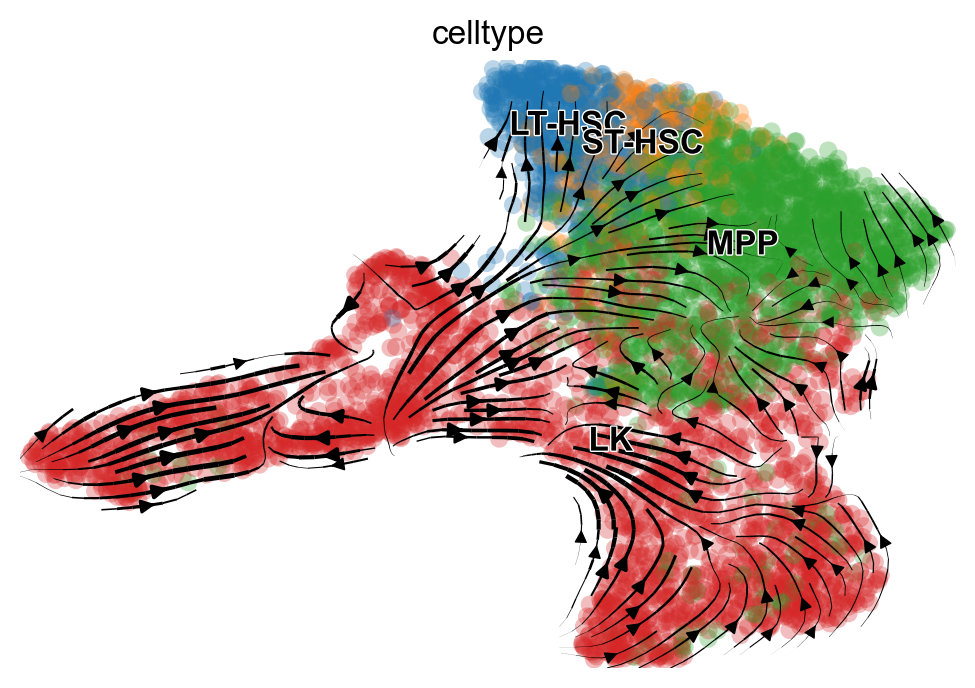

computing velocity graph (using 8/8 cores)


  0%|          | 0/5241 [00:00<?, ?cells/s]

    finished (0:00:13) --> added 
    'velo_s_norm_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:02) --> added
    'velo_s_norm_umap', embedded velocity vectors (adata.obsm)


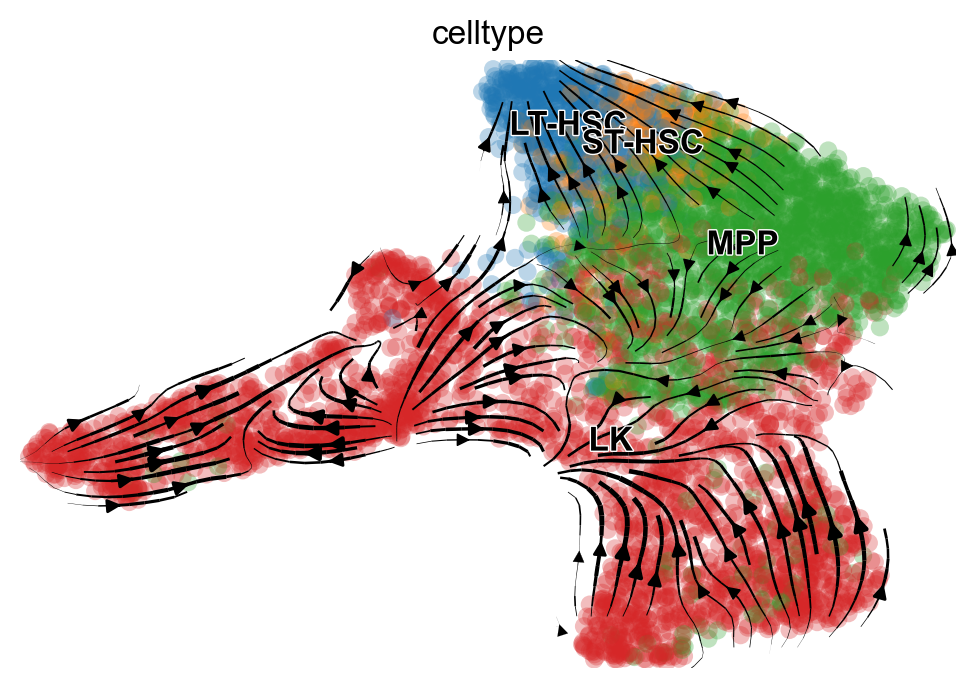

computing velocity graph (using 8/8 cores)


  0%|          | 0/5241 [00:00<?, ?cells/s]

    finished (0:00:14) --> added 
    'velo_s_norm_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:02) --> added
    'velo_s_norm_umap', embedded velocity vectors (adata.obsm)


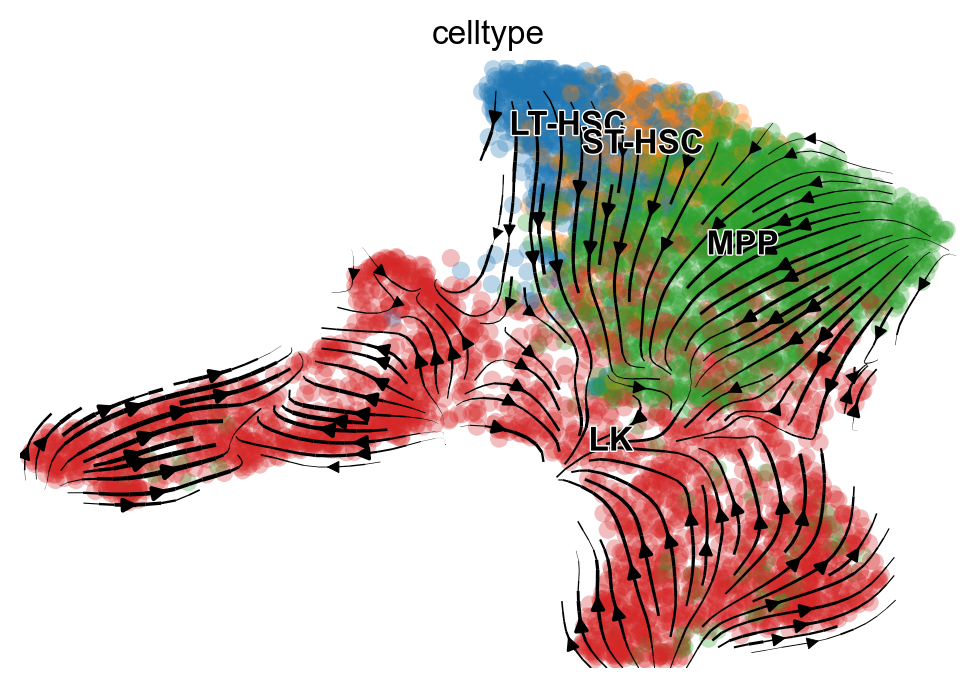

computing velocity graph (using 8/8 cores)


  0%|          | 0/5241 [00:00<?, ?cells/s]

    finished (0:00:16) --> added 
    'velo_s_norm_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:02) --> added
    'velo_s_norm_umap', embedded velocity vectors (adata.obsm)


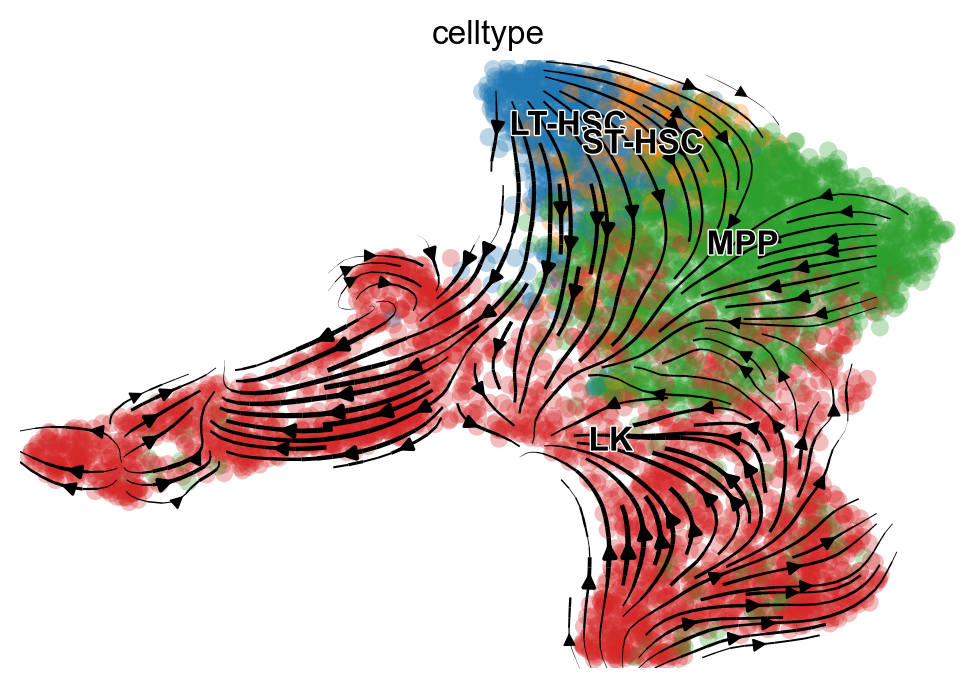

In [17]:
for s in [25, 50, 100, 200]:
    gene_subset = lt_t[:s].index.to_list()    
    sub = mv_data[:, gene_subset].copy()
    mv.velocity_graph(sub, n_jobs=8)
    mv.velocity_embedding_stream(sub, basis='umap', color='celltype')

## Comparison of Metric Distributions
To evaluate how discriminant the chosen metrics are between a high and low scorers, we plot the distributions and check for significant differences.

lik p-value: 7.369394636295537e-07
lik_c p-value: 0.0002538591782171774
rel_mag p-value: 7.753883873670064e-11
coverage p-value: 1.2625270277767564e-05


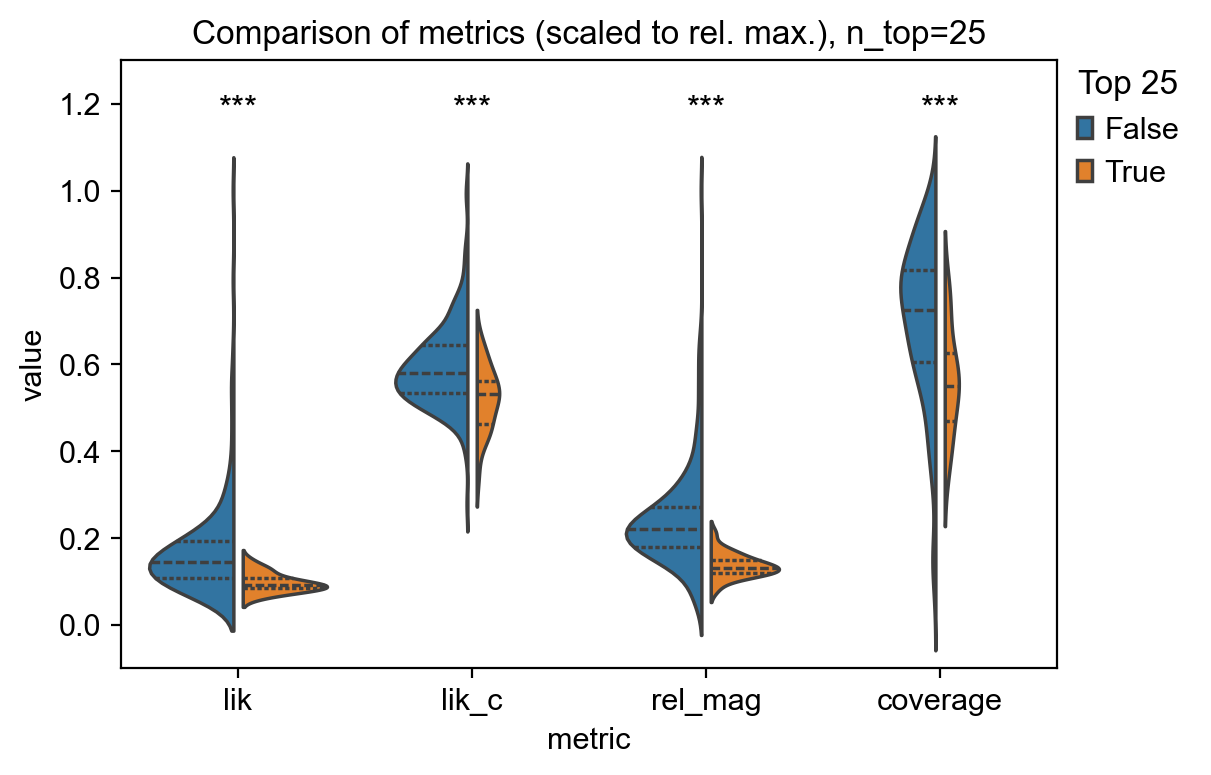

In [12]:
plot_df = lik_mag_cov.melt(
    id_vars="top25",
    value_vars=metrics,
    var_name="metric",
    value_name="value"
)
sns.violinplot(
    data=plot_df,
    x="metric",
    y="value",
    hue="top25",
    split=True, gap=.1, inner="quart",
)

for i, metric in enumerate(metrics): 
    stat, p = mannwhitneyu(lik_mag_cov.loc[lik_mag_cov["top25"], metric], lik_mag_cov.loc[~lik_mag_cov["top25"], metric])
    
    if p > 0.05: 
        star = "ns"
    elif 0.05 > p > 0.01:
        star = "*"
    elif 0.01 > p > 0.001: 
        star = "**"
    else: 
        star = "***"
    print(f"{metric} p-value: {p}")

    y = plot_df['value'].max() + 0.05
    plt.text(i, y+0.1, star, ha='center', va='bottom')

plt.ylim(-0.1,1.3)
plt.legend(bbox_to_anchor=(1.16, 1.03), title="Top 25", frameon=False)
plt.title(f"Comparison of metrics (scaled to rel. max.), n_top=25")
plt.show()

lik p-value: 6.382883600412785e-10
lik_c p-value: 0.0001773892409467794
rel_mag p-value: 1.5699373059899927e-11
coverage p-value: 6.043971815804165e-09


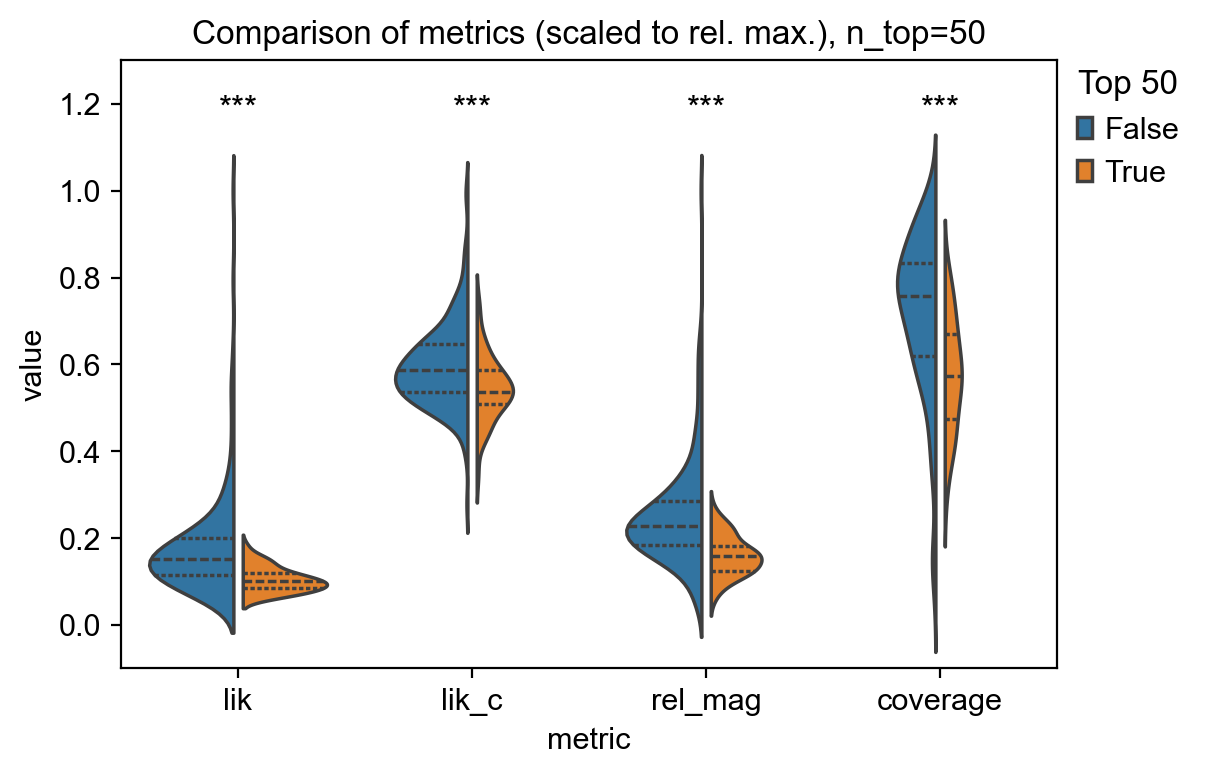

In [13]:
plot_df = lik_mag_cov.melt(
    id_vars="top50",
    value_vars=metrics,
    var_name="metric",
    value_name="value"
)
sns.violinplot(
    data=plot_df,
    x="metric",
    y="value",
    hue="top50",
    split=True, gap=.1, inner="quart"
)

for i, metric in enumerate(metrics): 
    stat, p = mannwhitneyu(lik_mag_cov.loc[lik_mag_cov["top50"], metric], lik_mag_cov.loc[~lik_mag_cov["top50"], metric])
    
    if p > 0.05: 
        star = "ns"
    elif 0.05 > p > 0.01:
        star = "*"
    elif 0.01 > p > 0.001: 
        star = "**"
    else: 
        star = "***"
    print(f"{metric} p-value: {p}")

    y = plot_df['value'].max() + 0.05
    plt.text(i, y+0.1, star, ha='center', va='bottom')

plt.ylim(-0.1,1.3)
plt.legend(bbox_to_anchor=(1.16, 1.03), title="Top 50", frameon=False)
plt.title(f"Comparison of metrics (scaled to rel. max.), n_top=50")
plt.show()

lik p-value: 1.674325533865138e-15
lik_c p-value: 6.349482497978055e-06
rel_mag p-value: 1.4555323631453508e-09
coverage p-value: 4.3577884478111844e-10


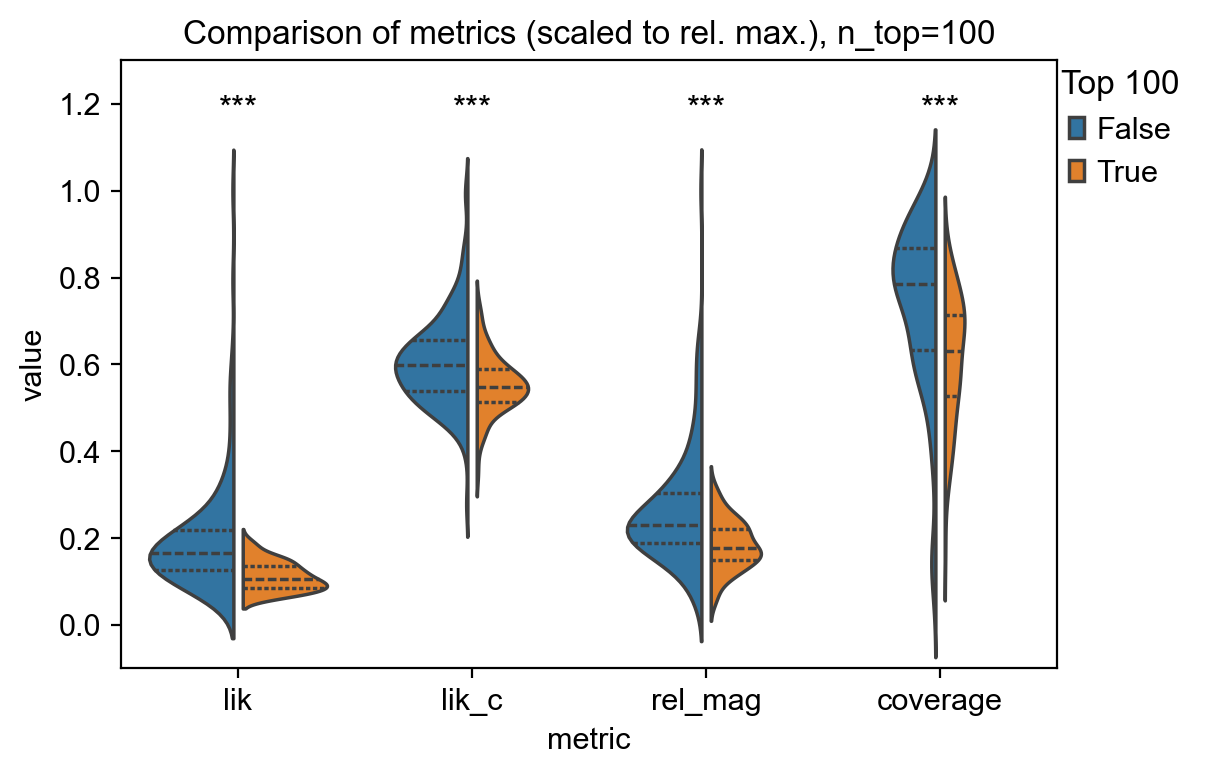

In [14]:
plot_df = lik_mag_cov.melt(
    id_vars="top100",
    value_vars=metrics,
    var_name="metric",
    value_name="value"
)
sns.violinplot(
    data=plot_df,
    x="metric",
    y="value",
    hue="top100",
    split=True, gap=.1, inner="quart"
)

for i, metric in enumerate(metrics): 
    stat, p = mannwhitneyu(lik_mag_cov.loc[lik_mag_cov["top100"], metric], lik_mag_cov.loc[~lik_mag_cov["top100"], metric])
    
    if p > 0.05: 
        star = "ns"
    elif 0.05 > p > 0.01:
        star = "*"
    elif 0.01 > p > 0.001: 
        star = "**"
    else: 
        star = "***"
    print(f"{metric} p-value: {p}")

    y = plot_df['value'].max() + 0.05
    plt.text(i, y+0.1, star, ha='center', va='bottom')

plt.ylim(-0.1,1.3)
plt.legend(bbox_to_anchor=(1.16, 1.03), title="Top 100", frameon=False)
plt.title(f"Comparison of metrics (scaled to rel. max.), n_top=100")
plt.show()

Save gene subsets to be used in ablation comparison

In [15]:
lik_mag_cov.to_csv(f"{python_data_dir}\mv_gene_ranking.csv")

## Trying to improve scVelo predictions with subsets (unsuccessful)

In [16]:
common = [g for g in df.index if g in adata_rna.var_names[adata_rna.var['velocity_genes']]]
V_mv = pd.DataFrame(mv_data[:, common].layers['velo_s'], index=mv_data.obs_names, columns=common)
V_sc = pd.DataFrame(adata_rna[mv_data.obs_names, common].layers['velocity'], index=mv_data.obs_names, columns=common)
agree = pd.Series({g: spearmanr(V_mv[g], V_sc[g], nan_policy='omit')[0] for g in common})

# 3. reciprocal rank fusion of all criteria (robust to scale differences)
def rrf(ranks_df, k=60):
    return (1.0 / (k + ranks_df)).sum(axis=1)

crit = pd.DataFrame({
    'lik': df.loc[common, 'lik'],
    'traj': res.loc[res.index.intersection(common), 'score'].rsub(res['score'].max()),  # higher=better
    'agree': agree,
}).dropna()
final = rrf(crit.rank(ascending=False)).sort_values(ascending=False)

computing moments based on connectivities
    finished (0:00:02) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
recovering dynamics (using 8/8 cores)


  0%|          | 0/425 [00:00<?, ?gene/s]

    finished (0:01:47) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
computing latent time using root_cells_manual, end_cells_manual as prior
    finished (0:00:05) --> added 
    'latent_time', shared time (adata.obs)
computing velocities
    finished (0:00:13) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/8 cores)


  0%|          | 0/5380 [00:00<?, ?cells/s]

    finished (0:00:09) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:02) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


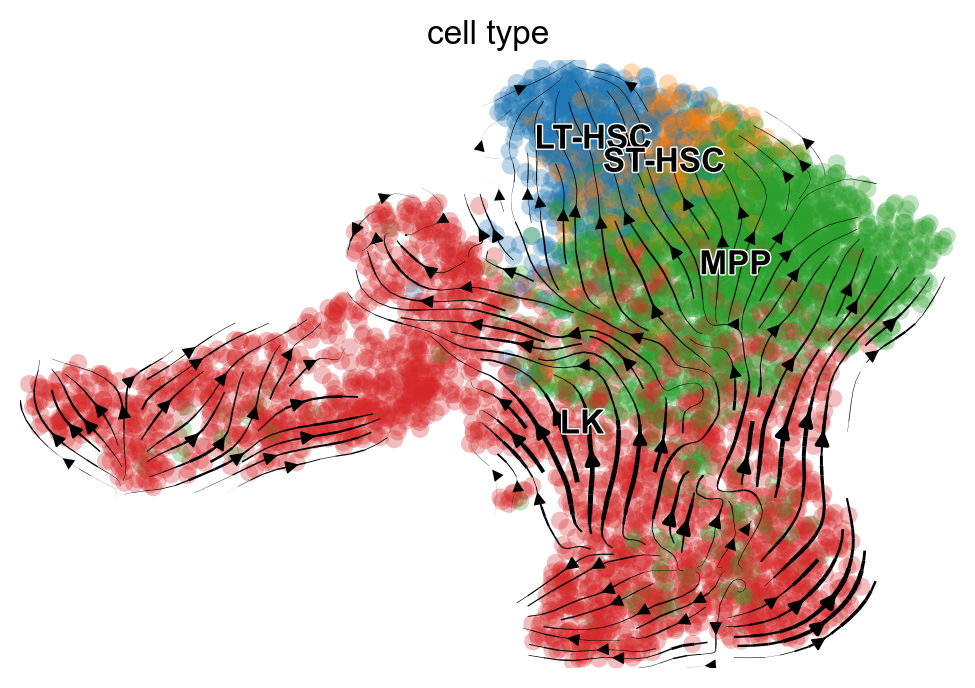

In [17]:
embedding_genes = pd.read_csv(rf"{python_data_dir}\peak_on_peaks_10_comps.csv", header=[0]).T.values.tolist()[0]

adata_rna.var['highly_variable'] = adata_rna.var_names.isin(embedding_genes)
scv.pp.moments(adata_rna, n_neighbors=10)

scv.tl.recover_dynamics(adata_rna, n_jobs=8)
scv.tl.latent_time(adata_rna, root_key="root_cells_manual", end_key="end_cells_manual")

scv.tl.velocity(adata_rna, mode='dynamical')
scv.tl.velocity_graph(adata_rna)

scv.pl.velocity_embedding_stream(adata_rna, basis='umap', color='cell_type')

83 genes selected
computing neighbors
    finished (0:00:15) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:02) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
recovering dynamics (using 8/8 cores)


  0%|          | 0/83 [00:00<?, ?gene/s]

    finished (0:02:23) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
fitted: 1420
computing velocities
    finished (0:00:12) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/8 cores)


  0%|          | 0/5380 [00:00<?, ?cells/s]

    finished (0:00:06) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
421 of 83 genes survived scVelo's filters
computing velocity embedding
    finished (0:00:02) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


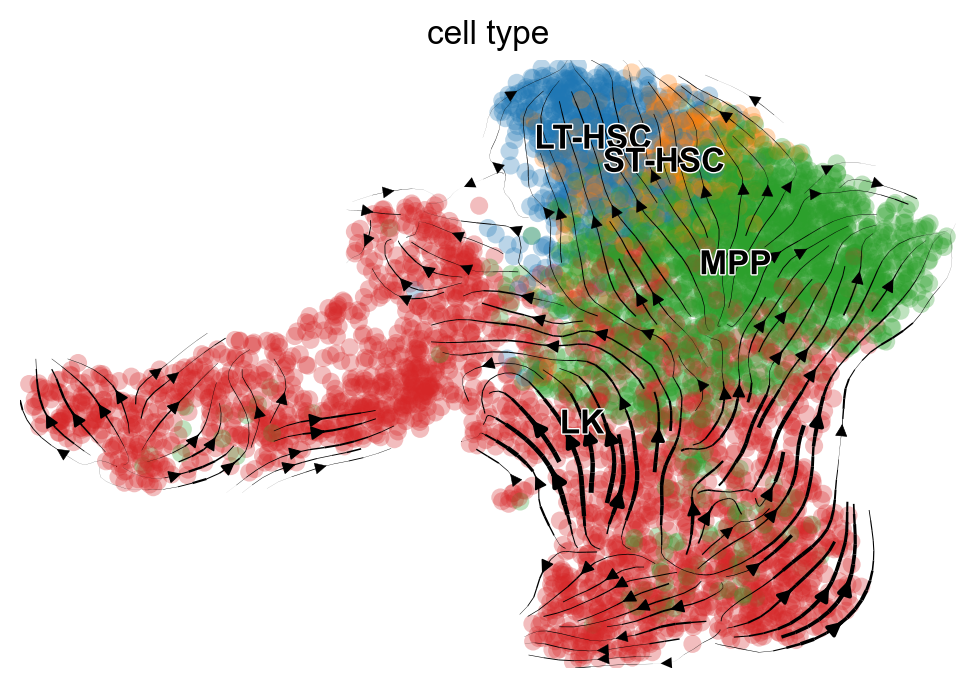

computing latent time using root_cells_manual, end_cells_manual as prior
    finished (0:00:05) --> added 
    'latent_time', shared time (adata.obs)


In [18]:
n_top = 100
selected = [g for g in final.index[:n_top] if g in adata_rna.var_names]
print(len(selected), "genes selected")

# neighbors on the embedding, then moments reuse them
scv.pp.neighbors(adata_rna, n_neighbors=10, use_rep="X_pca")
scv.pp.moments(adata_rna, n_neighbors=None)

# dynamical fit only on the selected genes
scv.tl.recover_dynamics(adata_rna, var_names=selected, n_jobs=8)
print("fitted:", adata_rna.var['fit_likelihood'].notnull().sum())

adata_rna.var['highly_variable'] = adata_rna.var_names.isin(selected)
scv.tl.velocity(adata_rna, mode='dynamical', use_highly_variable=True)
scv.tl.velocity_graph(adata_rna)

n_vel = adata_rna.var['velocity_genes'].sum()
print(f"{n_vel} of {len(selected)} genes survived scVelo's filters")

scv.pl.velocity_embedding_stream(adata_rna, basis='umap', color='cell_type')

# only now, if you want it
scv.tl.latent_time(adata_rna, root_key="root_cells_manual", end_key="end_cells_manual")